# 03 — Eligibility Features

**Dataset:** `data/processed/trials.parquet` (one row per interventional trial, AACT, start 2008–2020),
built by `scripts/03_build_dataset.py`.

**Goal:** turn the free-text eligibility criteria into measurable features that can be used in the prediction model, going beyond criteria length (the only eligibility feature so far).

**Questions this notebook answers**
1. How many inclusion and exclusion rules does a typical trial have?
2. How common are specific restriction types (organ function, prior cancer, pregnancy, etc.)?
3. Which restriction types are associated with termination for low enrollment (`label = 1`)?
4. Does a simple strictness score (number of restriction types) show a gradient in failure?

> Rates are computed on **labeled trials only** (1 = terminated for enrollment, 0 = completed) and are
> **unadjusted** for phase, sponsor, or disease area. Rule flags are keyword-based (v0), so they will
> miss some wordings and catch some false matches; an LLM-based extraction will refine them later.

## 1. Setup

Load the trial table and keep only labeled trials. `BASE` is the overall failure rate, used as a
reference line in plots.

In [22]:
# Turn free-text eligibility criteria into measurable features:
# rule counts and flags for common restriction types.

import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "notebooks" / "figures"

df = pd.read_parquet(ROOT / "data/processed/trials.parquet")
labeled = df[df["label"].notna()].copy()
BASE = labeled["label"].mean()
print(f"{len(labeled):,} labeled trials, base/failure rate {BASE:.2%}")

164,593 labeled trials, base/failure rate 4.79%


## 2. Split criteria into inclusion and exclusion and count the number of rules

Criteria text usually has an "Inclusion Criteria:" and an "Exclusion Criteria:" section, with each rule written as a bullet point. 
We split the text at "Exclusion Criteria" and count the bullet lines in each part. More rules may mean a smaller set of eligible patients.

In [4]:
# Criteria text usually looks like: "Inclusion Criteria: * ... Exclusion Criteria: * ..."
def split_criteria(text):
    if not isinstance(text, str):
        return "", ""
    parts = re.split(r"exclusion\s+criteria\s*:?", text, maxsplit=1, flags=re.I)
    inclusion = re.sub(r"inclusion\s+criteria\s*:?", "", parts[0], flags=re.I)
    exclusion = parts[1] if len(parts) > 1 else ""
    return inclusion, exclusion

def count_items(section):
    # Count bullet lines: "*", "-", "•", or numbered like "1." / "1)"
    return len(re.findall(r"^\s*(?:[\*\-•]|\d+[\.\)])\s+", section, flags=re.M))

parts = labeled["criteria"].map(split_criteria)
labeled["inclusion_text"] = parts.str[0]
labeled["exclusion_text"] = parts.str[1]
labeled["n_inclusion"] = labeled["inclusion_text"].map(count_items)
labeled["n_exclusion"] = labeled["exclusion_text"].map(count_items)
labeled["has_exclusion_section"] = labeled["exclusion_text"].str.len() > 0

labeled[["n_inclusion", "n_exclusion"]].describe(percentiles=[.25, .5, .75, .99]).round(1)

,n_inclusion,n_exclusion
count,164593.0,164593.0
mean,5.7,8.7
std,5.4,7.8
min,0.0,0.0
25%,3.0,3.0
50%,4.0,6.0
75%,7.0,12.0
99%,27.0,35.0
max,108.0,137.0


## 3. Flag common restriction types

Each trial is checked for about 12 types of restrictions using keyword patterns (for example, organ
function limits, prior cancer, pregnancy, or language requirements). The number of restriction types
present gives a simple **strictness score** from 0 to 12.

In [24]:
# Keyword patterns for ~12 rule types (searched in the full criteria text)
RULES = {
    "organ_function":     r"creatinine|egfr|renal function|bilirubin|\bast\b|\balt\b|hepatic function|liver function",
    "lab_threshold":      r"x\s*uln|×\s*uln|upper limit of normal|mg/dl|/mm3|g/dl|10\^9",
    "prior_malignancy":   r"prior malignan|other malignan|history of (?:cancer|malignan)|second (?:primary )?malignan",
    "prior_therapy":      r"prior (?:treatment|therapy|chemotherapy)|previously treated|previous (?:treatment|therapy)",
    "performance_status": r"ecog|karnofsky|performance status",
    "pregnancy":          r"pregnan|breast[- ]?feeding|lactating|contracepti",
    "infection":          r"\bhiv\b|hepatitis|\bhbv\b|\bhcv\b",
    "cardiac":            r"myocardial infarction|heart failure|qtc|arrhythmia|nyha",
    "cns_mets":           r"brain metasta|cns metasta|central nervous system metasta",
    "language_consent":   r"english|able to (?:read|understand)|cognitive impair|dementia",  
    "concomitant_meds":   r"concomitant|cyp3a|strong inhibitor|anticoagula",
    "substance_use":      r"alcohol|substance (?:abuse|use)|drug abuse",
}
for name, pattern in RULES.items():
    labeled[f"rule_{name}"] = labeled["criteria"].str.contains(pattern, case=False, regex=True, na=False)

rule_cols = [f"rule_{n}" for n in RULES]
labeled["n_rule_types"] = labeled[rule_cols].sum(axis=1)   # simple strictness score (0-12)

# How common is each rule type?
(labeled[rule_cols].mean() * 100).sort_values(ascending=False).round(1).to_frame("% of trials")

,% of trials
rule_pregnancy,50.6
rule_substance_use,20.8
rule_organ_function,19.5
rule_infection,19.1
rule_cardiac,18.2
rule_language_consent,17.6
rule_lab_threshold,16.3
rule_concomitant_meds,12.9
rule_performance_status,10.7
rule_prior_therapy,8.5


## 4. Which restriction types are linked to failure?

For each restriction type, compare the failure rate of trials that include it versus trials that
don't. A ratio above 1 means trials with that restriction fail more often (unadjusted).

In [25]:
# Failure rate with vs. without each rule type (unadjusted)
rows = []
for col in rule_cols:
    with_rule = labeled.loc[labeled[col], "label"]
    without = labeled.loc[~labeled[col], "label"]
    rows.append({"rule": col.replace("rule_", ""),
                 "n_with": len(with_rule),
                 "rate_with_%": with_rule.mean() * 100,
                 "rate_without_%": without.mean() * 100,
                 "ratio": with_rule.mean() / without.mean()})
rule_rates = pd.DataFrame(rows).sort_values("ratio", ascending=False).round(2)
rule_rates

# example: if performance status ratio is 2.88, it means trials with that rule fail almost three times as often.

,rule,n_with,rate_with_%,rate_without_%,ratio
4,performance_status,17678,11.47,3.99,2.88
3,prior_therapy,14051,9.74,4.33,2.25
8,cns_mets,6365,10.23,4.57,2.24
1,lab_threshold,26874,8.39,4.09,2.05
0,organ_function,32135,8.16,3.97,2.05
5,pregnancy,83335,6.19,3.35,1.85
2,prior_malignancy,10508,7.88,4.58,1.72
7,cardiac,29984,7.19,4.26,1.69
10,concomitant_meds,21298,7.39,4.40,1.68
6,infection,31364,6.01,4.50,1.34


## 5. Does failure rise with the strictness score?

If stricter criteria make recruiting harder, the failure rate should increase as the number of
restriction types increases. Groups with fewer than 100 trials are hidden because their rates are unstable.

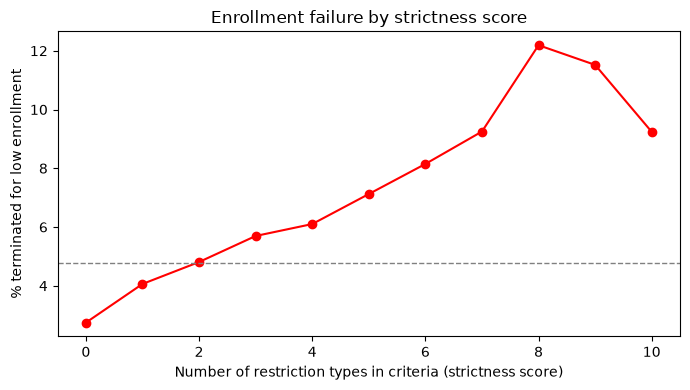

,n,rate
n_rule_types,,
0,42249,0.027
1,45471,0.041
2,27820,0.048
3,16417,0.057
4,10211,0.061
5,7300,0.071
6,5548,0.081
7,4151,0.093
8,2855,0.122


In [27]:
# Failure rate by number of rule types present (0-12)
score = labeled.groupby("n_rule_types")["label"].agg(n="size", rate="mean")
score = score[score["n"] >= 100]           # hide unstable groups

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(score.index, score["rate"] * 100, marker="o", color="red")
ax.axhline(BASE * 100, ls="--", color="gray", lw=1)
ax.set_xlabel("Number of restriction types in criteria (strictness score)")
ax.set_ylabel("% terminated for low enrollment")
ax.set_title("Enrollment failure by strictness score")
plt.tight_layout()
plt.savefig(FIG / "strictness_score.png", bbox_inches="tight", dpi=300)
plt.show()
score.round(3)

## 6. Save features

Save the trial IDs and new eligibility features to `data/processed/eligibility_features.parquet`,
so they can be merged into the modeling notebook.

In [14]:
# Save only IDs + new features, so teammates can merge them into the model
feature_cols = ["nct_id", "n_inclusion", "n_exclusion", "has_exclusion_section", "n_rule_types"] + rule_cols
labeled[feature_cols].to_parquet(ROOT / "data/processed/eligibility_features.parquet", index=False)
print("Saved", len(labeled), "rows")

Saved 164593 rows


## 7. Does the strictness score hold after adjustment?

Strict trials fail more often, but maybe that’s because of something else. For example, Phase 2 trials tend to have stricter rules and fail more often, so phase could be the real reason. Cell 7 checks whether strictness still matters once we account for these other factors.
A logistic regression with phase, sponsor class, healthy volunteers, and start year as controls shows
whether the strictness score is still linked to failure. Disease area is not yet included and will be
added once that feature is built.

In [ ]:
import statsmodels.formula.api as smf

# Prepare the data: fill missing categories and keep the main sponsor classes
m = labeled.copy()
m["phase"] = m["phase"].fillna("NA").astype(str)
m["lead_sponsor_class"] = m["lead_sponsor_class"].astype(str)
m["healthy_volunteers"] = m["healthy_volunteers"].astype(str)
m = m[m["lead_sponsor_class"].isin(["INDUSTRY", "OTHER", "NIH", "OTHER_GOV", "NETWORK", "FED"])]
m["year_c"] = m["start_year"] - 2014   # centred for numerical stability

# OR - Odds ratio, lo and hi - 95% confidence interval (range the true value likely falls in)
# Crude means looking at the strictness score alone, without accounting for anything else. It answers: “Do stricter trials fail more often?”
# Adjusted means looking at the strictness score while also accounting for other factors (phase, sponsor, healthy volunteers, start year). It answers: “Among trials that are similar in those ways, do stricter ones still fail more often?”

def odds_ratio(formula, term):
    # Fit a logistic regression and return the odds ratio and 95% CI for one term
    fit = smf.logit(formula, data=m).fit(disp=0)
    ci = np.exp(fit.conf_int().loc[term])
    return pd.Series({"OR": np.exp(fit.params[term]), "lo": ci[0], "hi": ci[1]})

crude = odds_ratio("label ~ n_rule_types", "n_rule_types")
adjusted = odds_ratio("label ~ n_rule_types + C(phase) + C(lead_sponsor_class)"
                      " + C(healthy_volunteers) + year_c", "n_rule_types")

print("Odds ratio per additional restriction type (OR > 1 = higher failure odds)")
pd.DataFrame({"crude": crude, "adjusted": adjusted}).T.round(3)

Odds ratio per additional restriction type (OR > 1 = higher failure odds)


,OR,lo,hi
crude,1.177,1.167,1.187
adjusted,1.140,1.127,1.152


## 8. Summary of findings

**Rule counts**
- A typical trial lists 4 inclusion and 6 exclusion rules (medians); the top 1% list 27+ inclusion and 35+ exclusion rules.

**Restriction types (keyword flags)**
- The most common restrictions are pregnancy (51%), substance use (21%), organ function (20%), and infection (19%).
- The restrictions most linked to failure are performance status (11.5% vs. 4.0%, 2.9×), prior therapy (2.3×),
  brain metastases (2.2×), lab thresholds (2.1×), and organ function (2.1×). These are typical of cancer trials,
  so part of the effect may reflect disease area, which is not yet adjusted for.
- Language and cognitive requirements show no link to failure (4.7% vs. 4.8%), but they may affect who enrolls,
  which the representation analysis will test.
- Substance-use exclusions are linked to lower failure (0.75×), likely because they are common in behavioral and
  healthy-volunteer studies.

**Strictness score**
- Failure rises steadily from 2.7% for trials with no restriction types to 12.2% with eight, about 4.5× higher.
- Each additional restriction type raises the odds of failure by 18% (OR 1.18, 95% CI 1.17–1.19), and by 14% after
  adjusting for phase, sponsor class, healthy volunteers, and start year (OR 1.14, 95% CI 1.13–1.15).

**Caveats**
- Keyword flags miss some wordings and catch some false matches; they should be validated on a hand-labeled
  sample and refined with LLM extraction.
- Associations are not yet adjusted for disease area.

**Next steps**
1. Add disease area and recheck the strictness effect within it.
2. Validate rule flags against ~300 hand-labeled trials (per-rule precision, recall, F1).
3. Add these features to the baseline vs. full prediction model.